In [1]:
import os
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
if cwd.name == 'url_corpus' and cwd.parent.name == 'notebooks':
    os.chdir(cwd.parent)

nb_dir = Path.cwd().resolve()
backend_root = nb_dir.parent if nb_dir.name == 'notebooks' else nb_dir
if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

print(f'Notebook CWD: {Path.cwd()}')
print(f'Backend root in sys.path: {backend_root}')


Notebook CWD: /Users/maksymiliansowula/Documents/Studia/3semestrmgr/Magisterka/PhisingDetector/backend/notebooks
Backend root in sys.path: /Users/maksymiliansowula/Documents/Studia/3semestrmgr/Magisterka/PhisingDetector/backend


# Detekcja Phishingu - Random Forest

Ten notebook zawiera implementację i analizę modelu Random Forest do wykrywania phishingu.

## 1. Import bibliotek i konfiguracja


In [2]:
import sys
cwd = Path.cwd().resolve(); os.chdir(cwd.parent) if cwd.name == 'url_corpus' and cwd.parent.name == 'notebooks' else None; nb_dir = Path.cwd().resolve(); backend_root = nb_dir.parent if nb_dir.name == 'notebooks' else nb_dir; sys.path.insert(0, str(backend_root)) if str(backend_root) not in sys.path else None

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import pickle

import importlib

if 'utils.resource_monitor' in sys.modules:
    importlib.reload(sys.modules['utils.resource_monitor'])

from utils.resource_monitor import ResourceMonitor

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, learning_curve, validation_curve
from sklearn.tree import plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           roc_auc_score, confusion_matrix, roc_curve)
from utils.feature_names import get_readable_name

import os
PLOTS_DIR = "../static/plots_url_corpus/random_forest"
MODELS_DIR = "../models/random_forest"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.figsize'] = (12, 7)

np.random.seed(42)

print("Biblioteki zostały zaimportowane pomyślnie!")


Biblioteki zostały zaimportowane pomyślnie!


## 2. Wczytanie i eksploracja danych


In [3]:
df_full = pd.read_csv('../data/url_corpus/dataset_full.csv')
df_optimized = pd.read_csv('../data/url_corpus/dataset_optimized.csv')

datasets = {
    'Pełny zbiór': df_full,
    'Zoptymalizowany zbiór': df_optimized
}

print("="*80)
print("DANE ZAŁADOWANE - PORÓWNANIE ZBIORÓW")
print("="*80)

for name, df in datasets.items():
    print(f"\n{name}:")
    print(f"  • Rozmiar zbioru: {df.shape}")
    print(f"  • Liczba cech: {df.shape[1]-1}")

    label_counts = df['phishing'].value_counts()
    print(f"  • Rozkład etykiet:")
    print(f"    - Bezpieczne: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
    print(f"    - Phishing: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")
    print(f"  • Brakujące wartości: {df.isnull().sum().sum()}")
    print(f"  • Duplikaty: {df.duplicated().sum()}")

print("\n" + "="*80)

DANE ZAŁADOWANE - PORÓWNANIE ZBIORÓW

Pełny zbiór:
  • Rozmiar zbioru: (100000, 105)
  • Liczba cech: 104
  • Rozkład etykiet:
    - Bezpieczne: 50,000 (50.0%)
    - Phishing: 50,000 (50.0%)
  • Brakujące wartości: 0
  • Duplikaty: 18987

Zoptymalizowany zbiór:
  • Rozmiar zbioru: (82509, 42)
  • Liczba cech: 41
  • Rozkład etykiet:
    - Bezpieczne: 45,581 (55.2%)
    - Phishing: 36,928 (44.8%)
  • Brakujące wartości: 0
  • Duplikaty: 0



## 3. Przygotowanie cech i etykiet


In [4]:
data_splits = {}

for name, df in datasets.items():
    X = df.iloc[:, :-1]
    y = df.iloc[:, -1]

    data_splits[name] = {
        'X': X,
        'y': y,
        'feature_count': X.shape[1]
    }

    print(f"\n{name}:")
    print(f"  • Liczba cech: {X.shape[1]}")
    print(f"  • Rozkład etykiet:")
    for label, count in y.value_counts().items():
        percentage = count / len(y) * 100
        label_name = "Brak Phisingu" if label == 0 else "Phishing"
        print(f"    {label} ({label_name}): {count:,} ({percentage:.1f}%)")


Pełny zbiór:
  • Liczba cech: 104
  • Rozkład etykiet:
    1 (Phishing): 50,000 (50.0%)
    0 (Brak Phisingu): 50,000 (50.0%)

Zoptymalizowany zbiór:
  • Liczba cech: 41
  • Rozkład etykiet:
    0 (Brak Phisingu): 45,581 (55.2%)
    1 (Phishing): 36,928 (44.8%)


## 4. Podział danych na zbiory uczący i testowy


In [5]:
train_test_data = {}

for name, data in data_splits.items():
    X = data['X']
    y = data['y']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    train_test_data[name] = {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test
    }

    print(f"\n{name}:")
    print(f"  • Zbiór uczący: {X_train.shape[0]:,} próbek ({X_train.shape[0]/len(X)*100:.1f}%)")
    print(f"  • Zbiór testowy: {X_test.shape[0]:,} próbek ({X_test.shape[0]/len(X)*100:.1f}%)")

    train_counts = y_train.value_counts()
    print(f"  • Rozkład klas (uczący):")
    print(f"    - Brak phishingu: {train_counts[0]:,} ({train_counts[0]/len(y_train)*100:.1f}%)")
    print(f"    - Phishing: {train_counts[1]:,} ({train_counts[1]/len(y_train)*100:.1f}%)")


Pełny zbiór:
  • Zbiór uczący: 80,000 próbek (80.0%)
  • Zbiór testowy: 20,000 próbek (20.0%)
  • Rozkład klas (uczący):
    - Brak phishingu: 40,000 (50.0%)
    - Phishing: 40,000 (50.0%)

Zoptymalizowany zbiór:
  • Zbiór uczący: 66,007 próbek (80.0%)
  • Zbiór testowy: 16,502 próbek (20.0%)
  • Rozkład klas (uczący):
    - Brak phishingu: 36,465 (55.2%)
    - Phishing: 29,542 (44.8%)


## 5. Optymalizacja hiperparametrów i trening modelu


In [6]:
param_grids = [
    {
        'name': 'Optymalizacja liczby drzew',
        'params': {
            'n_estimators': [100, 200, 300],
            'max_depth': [None],
            'min_samples_split': [2],
            'min_samples_leaf': [1],
            'max_features': ['sqrt']
        }
    },
    {
        'name': 'Optymalizacja głębokości',
        'params': {
            'n_estimators': [200],
            'max_depth': [10, 20, 30, None],
            'min_samples_split': [2],
            'min_samples_leaf': [1],
            'max_features': ['sqrt']
        }
    },
    {
        'name': 'Optymalizacja podziału węzłów',
        'params': {
            'n_estimators': [200],
            'max_depth': [None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4],
            'max_features': ['sqrt']
        }
    }
]

trained_models = {}

for dataset_name, data in train_test_data.items():
    print(f"\n{'='*80}")
    print(f"OPTYMALIZACJA HIPERPARAMETRÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train = data['X_train']
    y_train = data['y_train']

    best_overall_score = 0
    best_overall_params = None
    best_config_name = ""

    start_time = time.time()

    for i, grid_config in enumerate(param_grids):
        config_name = grid_config['name']
        param_grid = grid_config['params']

        combinations = (len(param_grid['n_estimators']) *
                       len(param_grid['max_depth']) *
                       len(param_grid['min_samples_split']) *
                       len(param_grid['min_samples_leaf']) *
                       len(param_grid['max_features']))

        print(f"\nKonfiguracja {i+1}/{len(param_grids)}: {config_name}")
        print(f"Testowanie {combinations} kombinacji parametrów...")

        config_start_time = time.time()

        grid_search = GridSearchCV(
            RandomForestClassifier(random_state=42, n_jobs=-1),
            param_grid,
            cv=5,
            scoring='roc_auc',
            n_jobs=-1,
            verbose=0
        )

        grid_search.fit(X_train, y_train)

        config_time = time.time() - config_start_time

        print(f"  • Najlepszy CV ROC-AUC: {grid_search.best_score_:.4f}")
        print(f"  • Czas: {config_time:.2f}s")

        if grid_search.best_score_ > best_overall_score:
            best_overall_score = grid_search.best_score_
            best_overall_params = grid_search.best_params_
            best_config_name = config_name

    optimization_time = time.time() - start_time

    print(f"\n{'-'*80}")
    print(f"WYNIKI OPTYMALIZACJI - {dataset_name}:")
    print(f"  • Całkowity czas optymalizacji: {optimization_time:.2f}s ({optimization_time/60:.1f} min)")
    print(f"  • Najlepszy CV ROC-AUC: {best_overall_score:.4f}")
    print(f"  • Najlepsza konfiguracja: {best_config_name}")
    print(f"  • Najlepsze parametry: {best_overall_params}")

    trained_models[dataset_name] = {
        'params': best_overall_params,
        'cv_score': best_overall_score,
        'config_name': best_config_name,
        'optimization_time': optimization_time
    }

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW OPTYMALIZACJI")
print(f"{'='*80}")
for name, results in trained_models.items():
    print(f"\n{name}:")
    print(f"  • CV ROC-AUC: {results['cv_score']:.4f}")
    print(f"  • Czas optymalizacji: {results['optimization_time']:.2f}s")


OPTYMALIZACJA HIPERPARAMETRÓW - PEŁNY ZBIÓR

Konfiguracja 1/3: Optymalizacja liczby drzew
Testowanie 3 kombinacji parametrów...
  • Najlepszy CV ROC-AUC: 1.0000
  • Czas: 48.30s

Konfiguracja 2/3: Optymalizacja głębokości
Testowanie 4 kombinacji parametrów...
  • Najlepszy CV ROC-AUC: 1.0000
  • Czas: 47.54s

Konfiguracja 3/3: Optymalizacja podziału węzłów
Testowanie 9 kombinacji parametrów...
  • Najlepszy CV ROC-AUC: 1.0000
  • Czas: 63.72s

--------------------------------------------------------------------------------
WYNIKI OPTYMALIZACJI - Pełny zbiór:
  • Całkowity czas optymalizacji: 159.57s (2.7 min)
  • Najlepszy CV ROC-AUC: 1.0000
  • Najlepsza konfiguracja: Optymalizacja liczby drzew
  • Najlepsze parametry: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

OPTYMALIZACJA HIPERPARAMETRÓW - ZOPTYMALIZOWANY ZBIÓR

Konfiguracja 1/3: Optymalizacja liczby drzew
Testowanie 3 kombinacji parametrów...
  • Najlepszy CV R

## 5.1. Trening i monitorowanie zasobów systemowych (RAM i CPU)


In [7]:
resource_stats = {}

for dataset_name, data in train_test_data.items():
    print(f"\n{'='*80}")
    print(f"TRENING MODELU Z MONITOROWANIEM ZASOBÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train = data['X_train']
    y_train = data['y_train']

    print(f"Trenowanie na pełnym zbiorze uczącym: {X_train.shape[0]} próbek, {X_train.shape[1]} cech")

    best_params = trained_models[dataset_name]['params']

    monitor = ResourceMonitor(interval=0.1, debug=False)
    monitor.start()

    training_start = time.time()
    model = RandomForestClassifier(random_state=42, n_jobs=-1, **best_params)
    model.fit(X_train, y_train)
    training_time = time.time() - training_start

    monitor.stop()

    stats = monitor.get_stats()

    resource_stats[dataset_name] = {
        'monitor': monitor,
        'stats': stats
    }

    trained_models[dataset_name]['model'] = model
    trained_models[dataset_name]['training_time'] = training_time

    print(f"\n{'-'*80}")
    print(f"WYNIKI TRENINGU - {dataset_name}:")
    print(f"  • Czas treningu: {training_time:.2f}s")
    print(f"  • Liczba próbek monitorowania: {stats['samples']}")
    print(f"  • CPU:")
    print(f"    - Min: {stats['cpu']['min']:.1f}%")
    print(f"    - Max: {stats['cpu']['max']:.1f}%")
    print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
    print(f"  • RAM:")
    print(f"    - Min: {stats['ram']['min']:.2f} GB")
    print(f"    - Max: {stats['ram']['max']:.2f} GB")
    print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")


TRENING MODELU Z MONITOROWANIEM ZASOBÓW - PEŁNY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 80000 próbek, 104 cech

--------------------------------------------------------------------------------
WYNIKI TRENINGU - Pełny zbiór:
  • Czas treningu: 3.40s
  • Liczba próbek monitorowania: 18
  • CPU:
    - Min: 0.0%
    - Max: 19.8%
    - Średnia: 10.2%
  • RAM:
    - Min: 0.42 GB
    - Max: 0.58 GB
    - Średnia: 0.48 GB

TRENING MODELU Z MONITOROWANIEM ZASOBÓW - ZOPTYMALIZOWANY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 66007 próbek, 41 cech

--------------------------------------------------------------------------------
WYNIKI TRENINGU - Zoptymalizowany zbiór:
  • Czas treningu: 3.44s
  • Liczba próbek monitorowania: 21
  • CPU:
    - Min: 0.0%
    - Max: 32.5%
    - Średnia: 12.6%
  • RAM:
    - Min: 0.40 GB
    - Max: 0.49 GB
    - Średnia: 0.43 GB


## 5.2. Wizualizacja wykorzystania zasobów systemowych


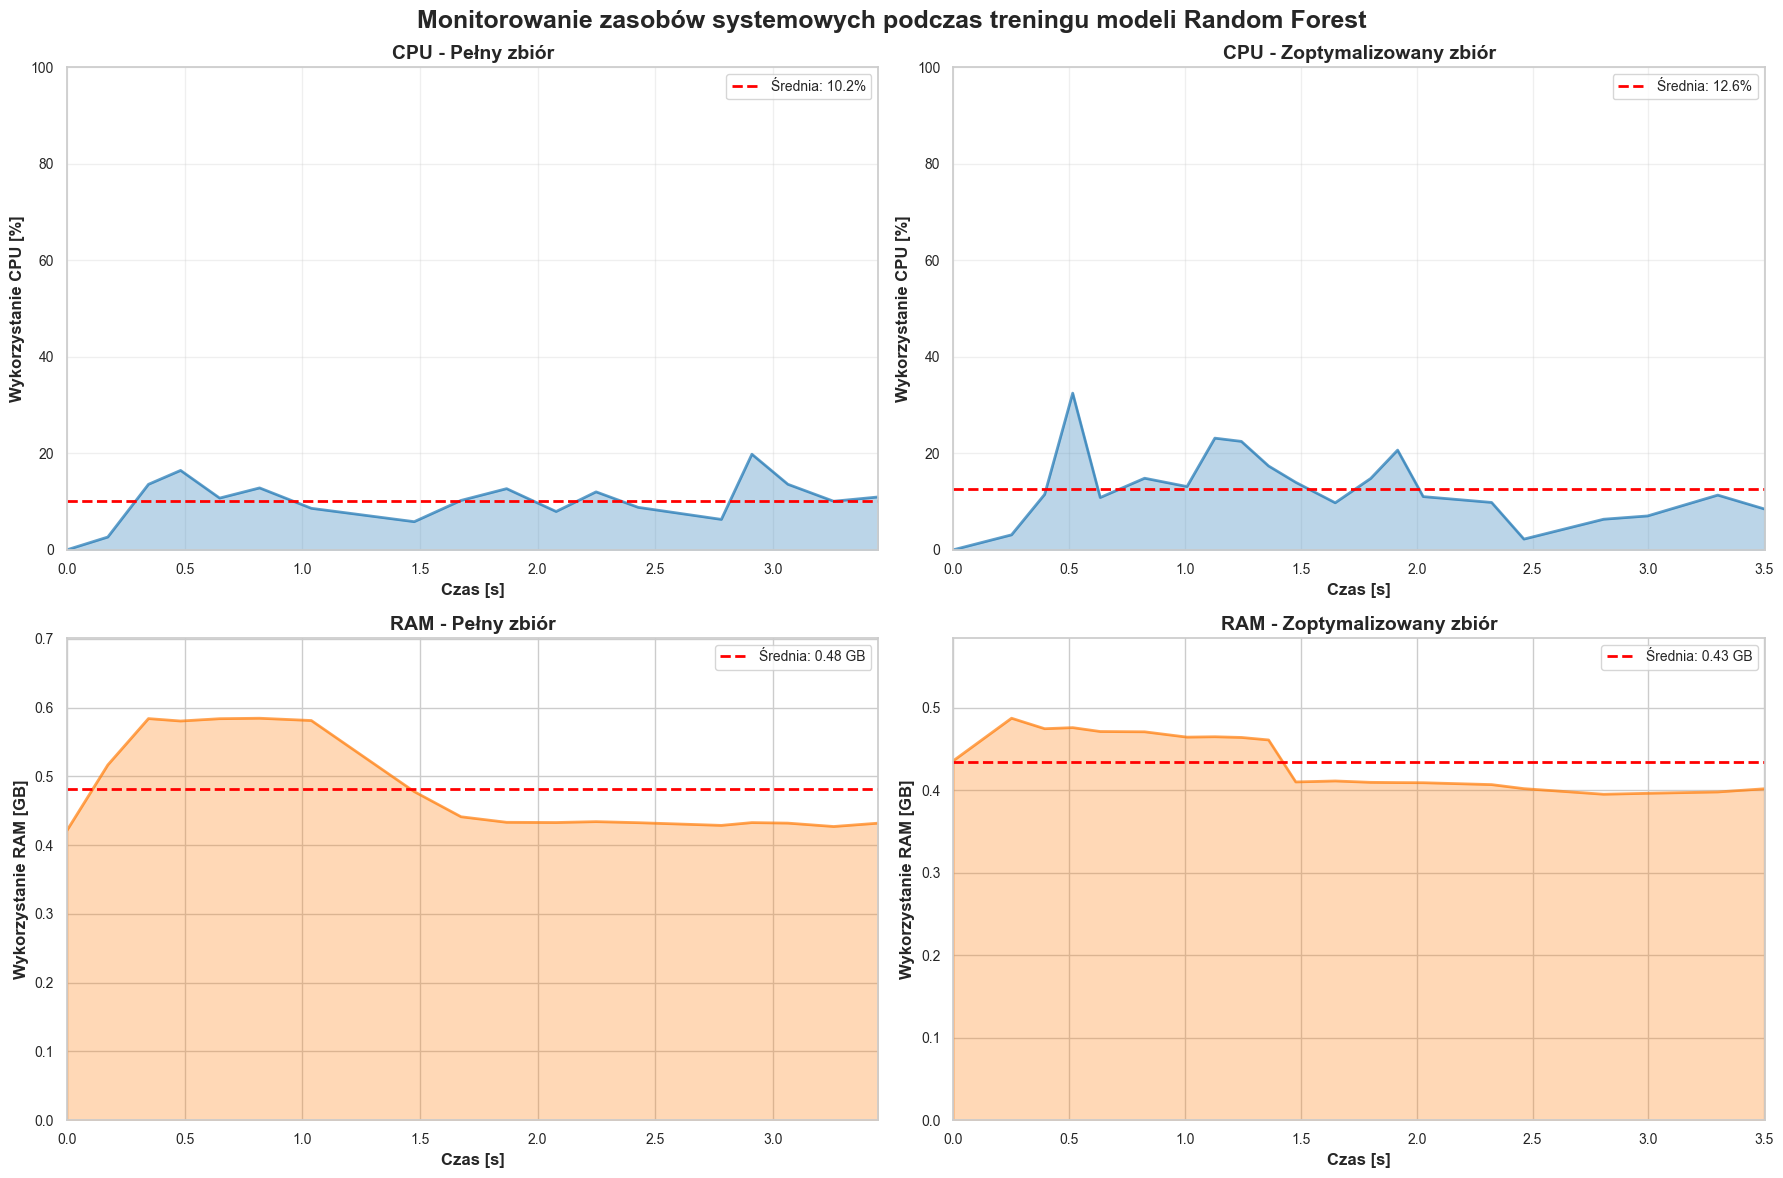

✅ Wizualizacja wykorzystania zasobów zapisana


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Monitorowanie zasobów systemowych podczas treningu modeli Random Forest', fontsize=18, fontweight='bold')

dataset_names = list(resource_stats.keys())

for idx, dataset_name in enumerate(dataset_names):
    monitor = resource_stats[dataset_name]['monitor']
    stats = resource_stats[dataset_name]['stats']

    if stats and len(monitor.timestamps) > 0:
        time_array = np.array(monitor.timestamps)
        time_array = time_array - time_array[0]
        cpu_array = np.array(monitor.cpu_percent)
        ram_array = np.array(monitor.ram_gb)

        axes[0, idx].plot(time_array, cpu_array, color='#1f77b4', linewidth=2, alpha=0.7)
        axes[0, idx].axhline(y=stats['cpu']['mean'], color='red', linestyle='--',
                            linewidth=2, label=f'Średnia: {stats["cpu"]["mean"]:.1f}%')
        axes[0, idx].fill_between(time_array, cpu_array, alpha=0.3, color='#1f77b4')
        axes[0, idx].set_xlabel('Czas [s]', fontsize=12, fontweight='bold')
        axes[0, idx].set_ylabel('Wykorzystanie CPU [%]', fontsize=12, fontweight='bold')
        axes[0, idx].set_title(f'CPU - {dataset_name}', fontweight='bold', fontsize=14)
        axes[0, idx].legend(fontsize=10)
        axes[0, idx].grid(True, alpha=0.3)
        axes[0, idx].set_xlim([0, time_array[-1]])
        axes[0, idx].set_ylim([0, max(100, stats['cpu']['max'] * 1.1)])

        axes[1, idx].plot(time_array, ram_array, color='#ff7f0e', linewidth=2, alpha=0.7)
        axes[1, idx].axhline(y=stats['ram']['mean'], color='red', linestyle='--',
                            linewidth=2, label=f'Średnia: {stats["ram"]["mean"]:.2f} GB')
        axes[1, idx].fill_between(time_array, ram_array, alpha=0.3, color='#ff7f0e')
        axes[1, idx].set_xlabel('Czas [s]', fontsize=12, fontweight='bold')
        axes[1, idx].set_ylabel('Wykorzystanie RAM [GB]', fontsize=12, fontweight='bold')
        axes[1, idx].set_title(f'RAM - {dataset_name}', fontweight='bold', fontsize=14)
        axes[1, idx].legend(fontsize=10)
        axes[1, idx].set_xlim([0, time_array[-1]])
        axes[1, idx].set_ylim([0, stats['ram']['max'] * 1.2])

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/random_forest_resource_usage_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


print("✅ Wizualizacja wykorzystania zasobów zapisana")

## 6. Ewaluacja modelu


In [9]:
evaluation_results = {}

for dataset_name, model_data in trained_models.items():
    print(f"\n{'='*80}")
    print(f"EWALUACJA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = model_data['model']
    data = train_test_data[dataset_name]

    X_test = data['X_test']
    y_test = data['y_test']
    X_train = data['X_train']
    y_train = data['y_train']

    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_roc = roc_auc_score(y_test, y_pred_proba)

    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')

    evaluation_results[dataset_name] = {
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc_roc': auc_roc,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }

    print(f"\nWYNIKI NA ZBIORZE TESTOWYM:")
    print(f"  • Dokładność (Accuracy): {accuracy:.4f}")
    print(f"  • Precyzja (Precision): {precision:.4f}")
    print(f"  • Czułość (Recall): {recall:.4f}")
    print(f"  • Miara F1 (F1-Score): {f1:.4f}")
    print(f"  • AUC-ROC: {auc_roc:.4f}")

    print(f"\nMACIERZ POMYŁEK:")
    print(f"  • Prawdziwie negatywne (TN): {tn:,}")
    print(f"  • Fałszywie pozytywne (FP): {fp:,}")
    print(f"  • Fałszywie negatywne (FN): {fn:,}")
    print(f"  • Prawdziwie pozytywne (TP): {tp:,}")

    print(f"\nPIĘCIOKROTNA WALIDACJA KRZYŻOWA:")
    print(f"  • Średni wynik ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  • Min: {cv_scores.min():.4f}")
    print(f"  • Max: {cv_scores.max():.4f}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW")
print(f"{'='*80}")
print(f"{'Metryka':<20} {'Pełny zbiór':>15} {'Zoptymalizowany zbiór':>20}")
print(f"{'-'*80}")
for metric in ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']:
    full_val = evaluation_results['Pełny zbiór'][metric]
    opt_val = evaluation_results['Zoptymalizowany zbiór'][metric]
    diff = opt_val - full_val
    diff_str = f"({diff:+.4f})" if diff != 0 else ""
    print(f"{metric.capitalize():<20} {full_val:>15.4f} {opt_val:>15.4f} {diff_str:>5}")


EWALUACJA MODELU - PEŁNY ZBIÓR

WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9999
  • Precyzja (Precision): 1.0000
  • Czułość (Recall): 0.9997
  • Miara F1 (F1-Score): 0.9998
  • AUC-ROC: 1.0000

MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 10,000
  • Fałszywie pozytywne (FP): 0
  • Fałszywie negatywne (FN): 3
  • Prawdziwie pozytywne (TP): 9,997

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 1.0000 ± 0.0000
  • Min: 1.0000
  • Max: 1.0000

EWALUACJA MODELU - ZOPTYMALIZOWANY ZBIÓR

WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9999
  • Precyzja (Precision): 1.0000
  • Czułość (Recall): 0.9999
  • Miara F1 (F1-Score): 0.9999
  • AUC-ROC: 1.0000

MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 9,116
  • Fałszywie pozytywne (FP): 0
  • Fałszywie negatywne (FN): 1
  • Prawdziwie pozytywne (TP): 7,385

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 1.0000 ± 0.0000
  • Min: 1.0000
  • Max: 1.0000

PORÓWNANIE WYNIKÓW
Metryka                

## 7. Wizualizacja kompleksowa i krzywa uczenia


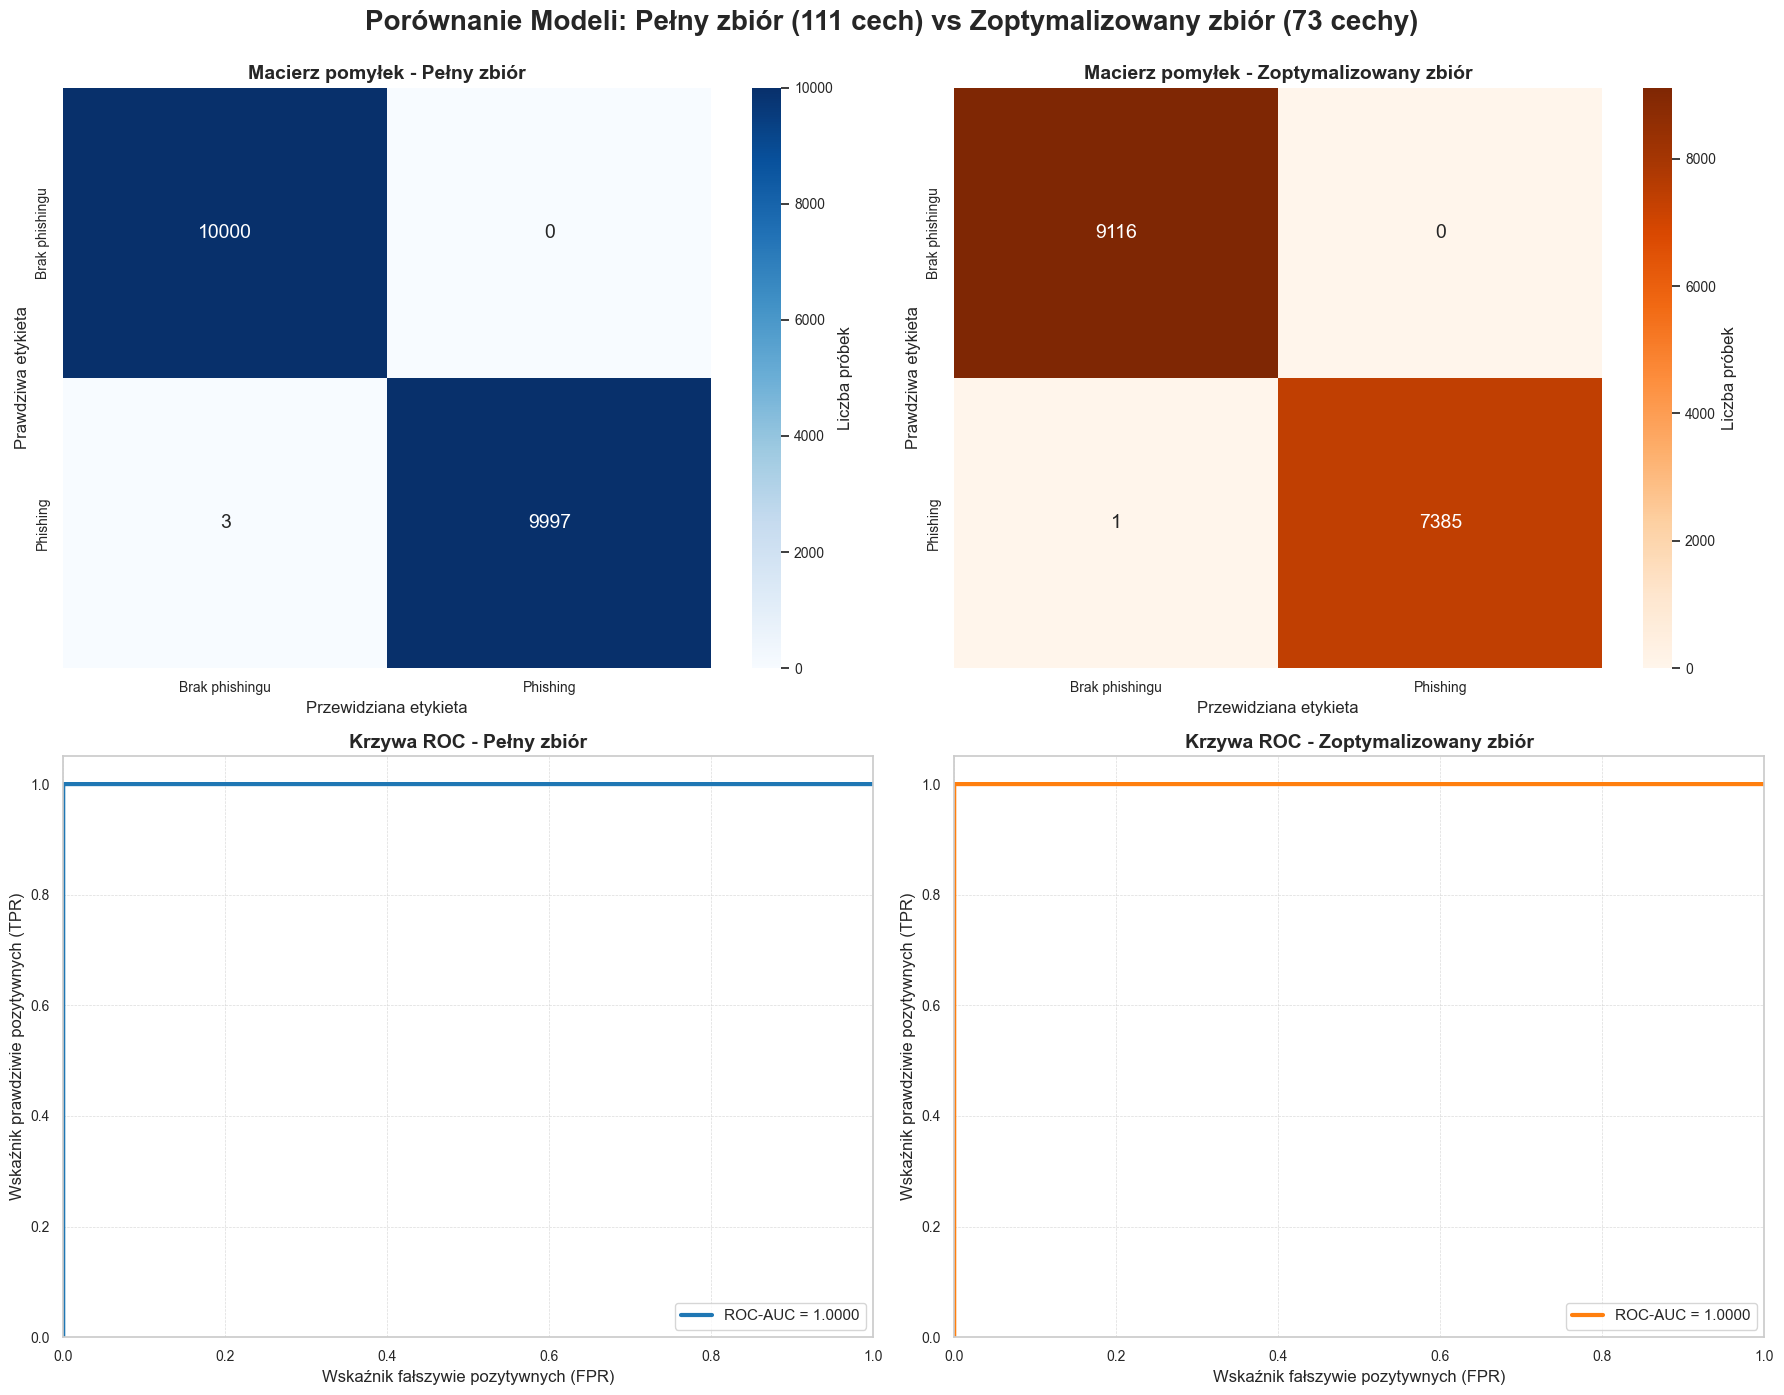

✅ Wizualizacja porównawcza zapisana


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Porównanie Modeli: Pełny zbiór (111 cech) vs Zoptymalizowany zbiór (73 cechy)', fontsize=20, fontweight='bold', y=0.995)

dataset_names = list(trained_models.keys())

for idx, dataset_name in enumerate(dataset_names):
    cm = evaluation_results[dataset_name]['confusion_matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues' if idx == 0 else 'Oranges',
                xticklabels=['Brak phishingu', 'Phishing'],
                yticklabels=['Brak phishingu', 'Phishing'],
                ax=axes[0, idx], annot_kws={"size": 14}, cbar_kws={'label': 'Liczba próbek'})
    axes[0, idx].set_title(f'Macierz pomyłek - {dataset_name}', fontweight='bold', fontsize=14)
    axes[0, idx].set_ylabel('Prawdziwa etykieta')
    axes[0, idx].set_xlabel('Przewidziana etykieta')

for idx, dataset_name in enumerate(dataset_names):
    y_test = train_test_data[dataset_name]['y_test']
    y_pred_proba = evaluation_results[dataset_name]['y_pred_proba']
    auc_roc = evaluation_results[dataset_name]['auc_roc']

    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    color = '#1f77b4' if idx == 0 else '#ff7f0e'
    axes[1, idx].plot(fpr, tpr, color=color, lw=3, label=f'ROC-AUC = {auc_roc:.4f}')
    axes[1, idx].set_xlim([0.0, 1.0])
    axes[1, idx].set_ylim([0.0, 1.05])
    axes[1, idx].set_xlabel('Wskaźnik fałszywie pozytywnych (FPR)', fontsize=12)
    axes[1, idx].set_ylabel('Wskaźnik prawdziwie pozytywnych (TPR)', fontsize=12)
    axes[1, idx].set_title(f'Krzywa ROC - {dataset_name}', fontweight='bold', fontsize=14)
    axes[1, idx].legend(loc="lower right", fontsize=11)
    axes[1, idx].grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/random_forest_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja porównawcza zapisana")

## 7.1. Porównanie metryk w postaci wykresów słupkowych


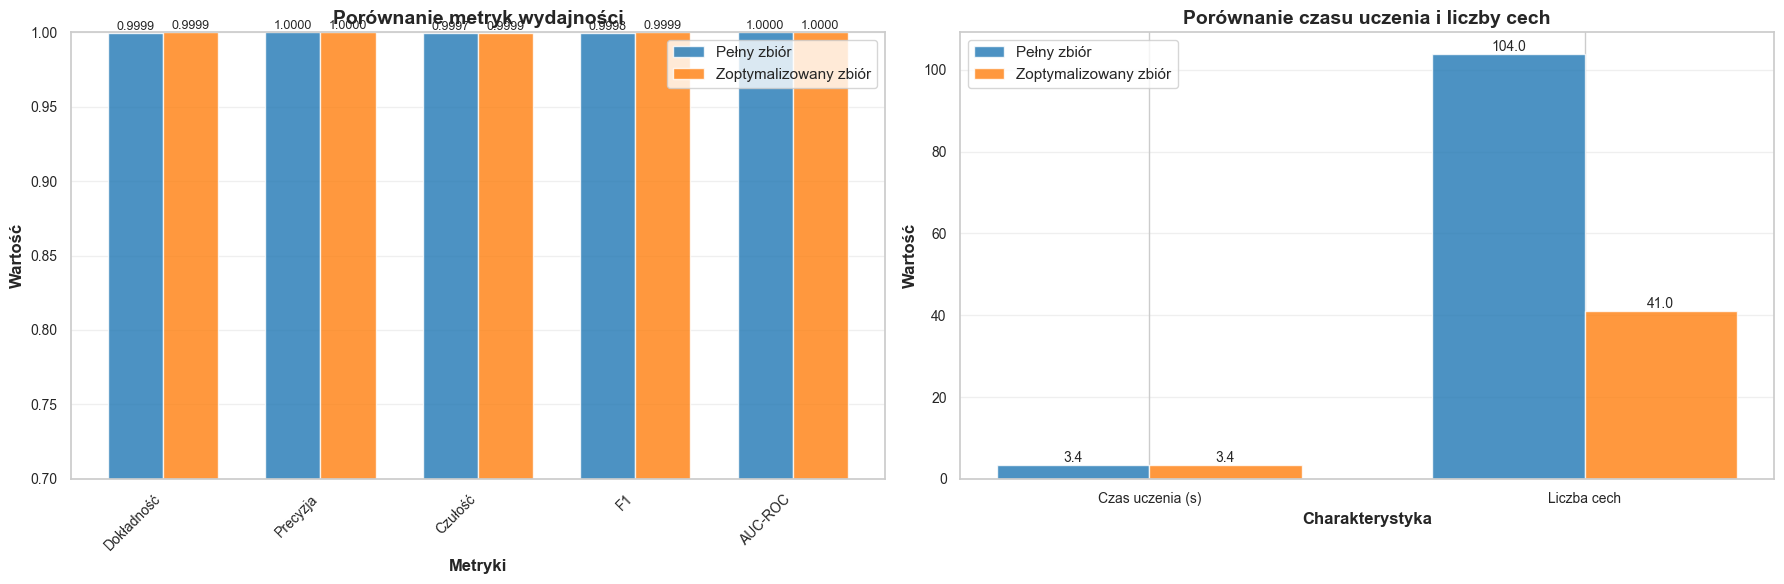

✅ Wizualizacja metryk zapisana


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

metrics = ['Dokładność', 'Precyzja', 'Czułość', 'F1', 'AUC-ROC']
metric_keys = ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']
full_values = [evaluation_results['Pełny zbiór'][key] for key in metric_keys]
opt_values = [evaluation_results['Zoptymalizowany zbiór'][key] for key in metric_keys]

x = np.arange(len(metrics))
width = 0.35

bars1 = axes[0].bar(x - width/2, full_values, width, label='Pełny zbiór', color='#1f77b4', alpha=0.8)
bars2 = axes[0].bar(x + width/2, opt_values, width, label='Zoptymalizowany zbiór', color='#ff7f0e', alpha=0.8)

axes[0].set_xlabel('Metryki', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Wartość', fontsize=12, fontweight='bold')
axes[0].set_title('Porównanie metryk wydajności', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics, rotation=45, ha='right')
axes[0].legend(fontsize=11)
axes[0].set_ylim([0.7, 1.0])
axes[0].grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.4f}',
                    ha='center', va='bottom', fontsize=9)

labels = ['Czas uczenia (s)', 'Liczba cech']
full_stats = [
    trained_models['Pełny zbiór']['training_time'],
    data_splits['Pełny zbiór']['feature_count']
]
opt_stats = [
    trained_models['Zoptymalizowany zbiór']['training_time'],
    data_splits['Zoptymalizowany zbiór']['feature_count']
]

x_pos = np.arange(len(labels))
bars1 = axes[1].bar(x_pos - width/2, full_stats, width, label='Pełny zbiór', color='#1f77b4', alpha=0.8)
bars2 = axes[1].bar(x_pos + width/2, opt_stats, width, label='Zoptymalizowany zbiór', color='#ff7f0e', alpha=0.8)

axes[1].set_xlabel('Charakterystyka', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Wartość', fontsize=12, fontweight='bold')
axes[1].set_title('Porównanie czasu uczenia i liczby cech', fontsize=14, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}',
                    ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/random_forest_metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja metryk zapisana")

## 7.1a. Wizualizacja przykładowego drzewa decyzyjnego z lasu


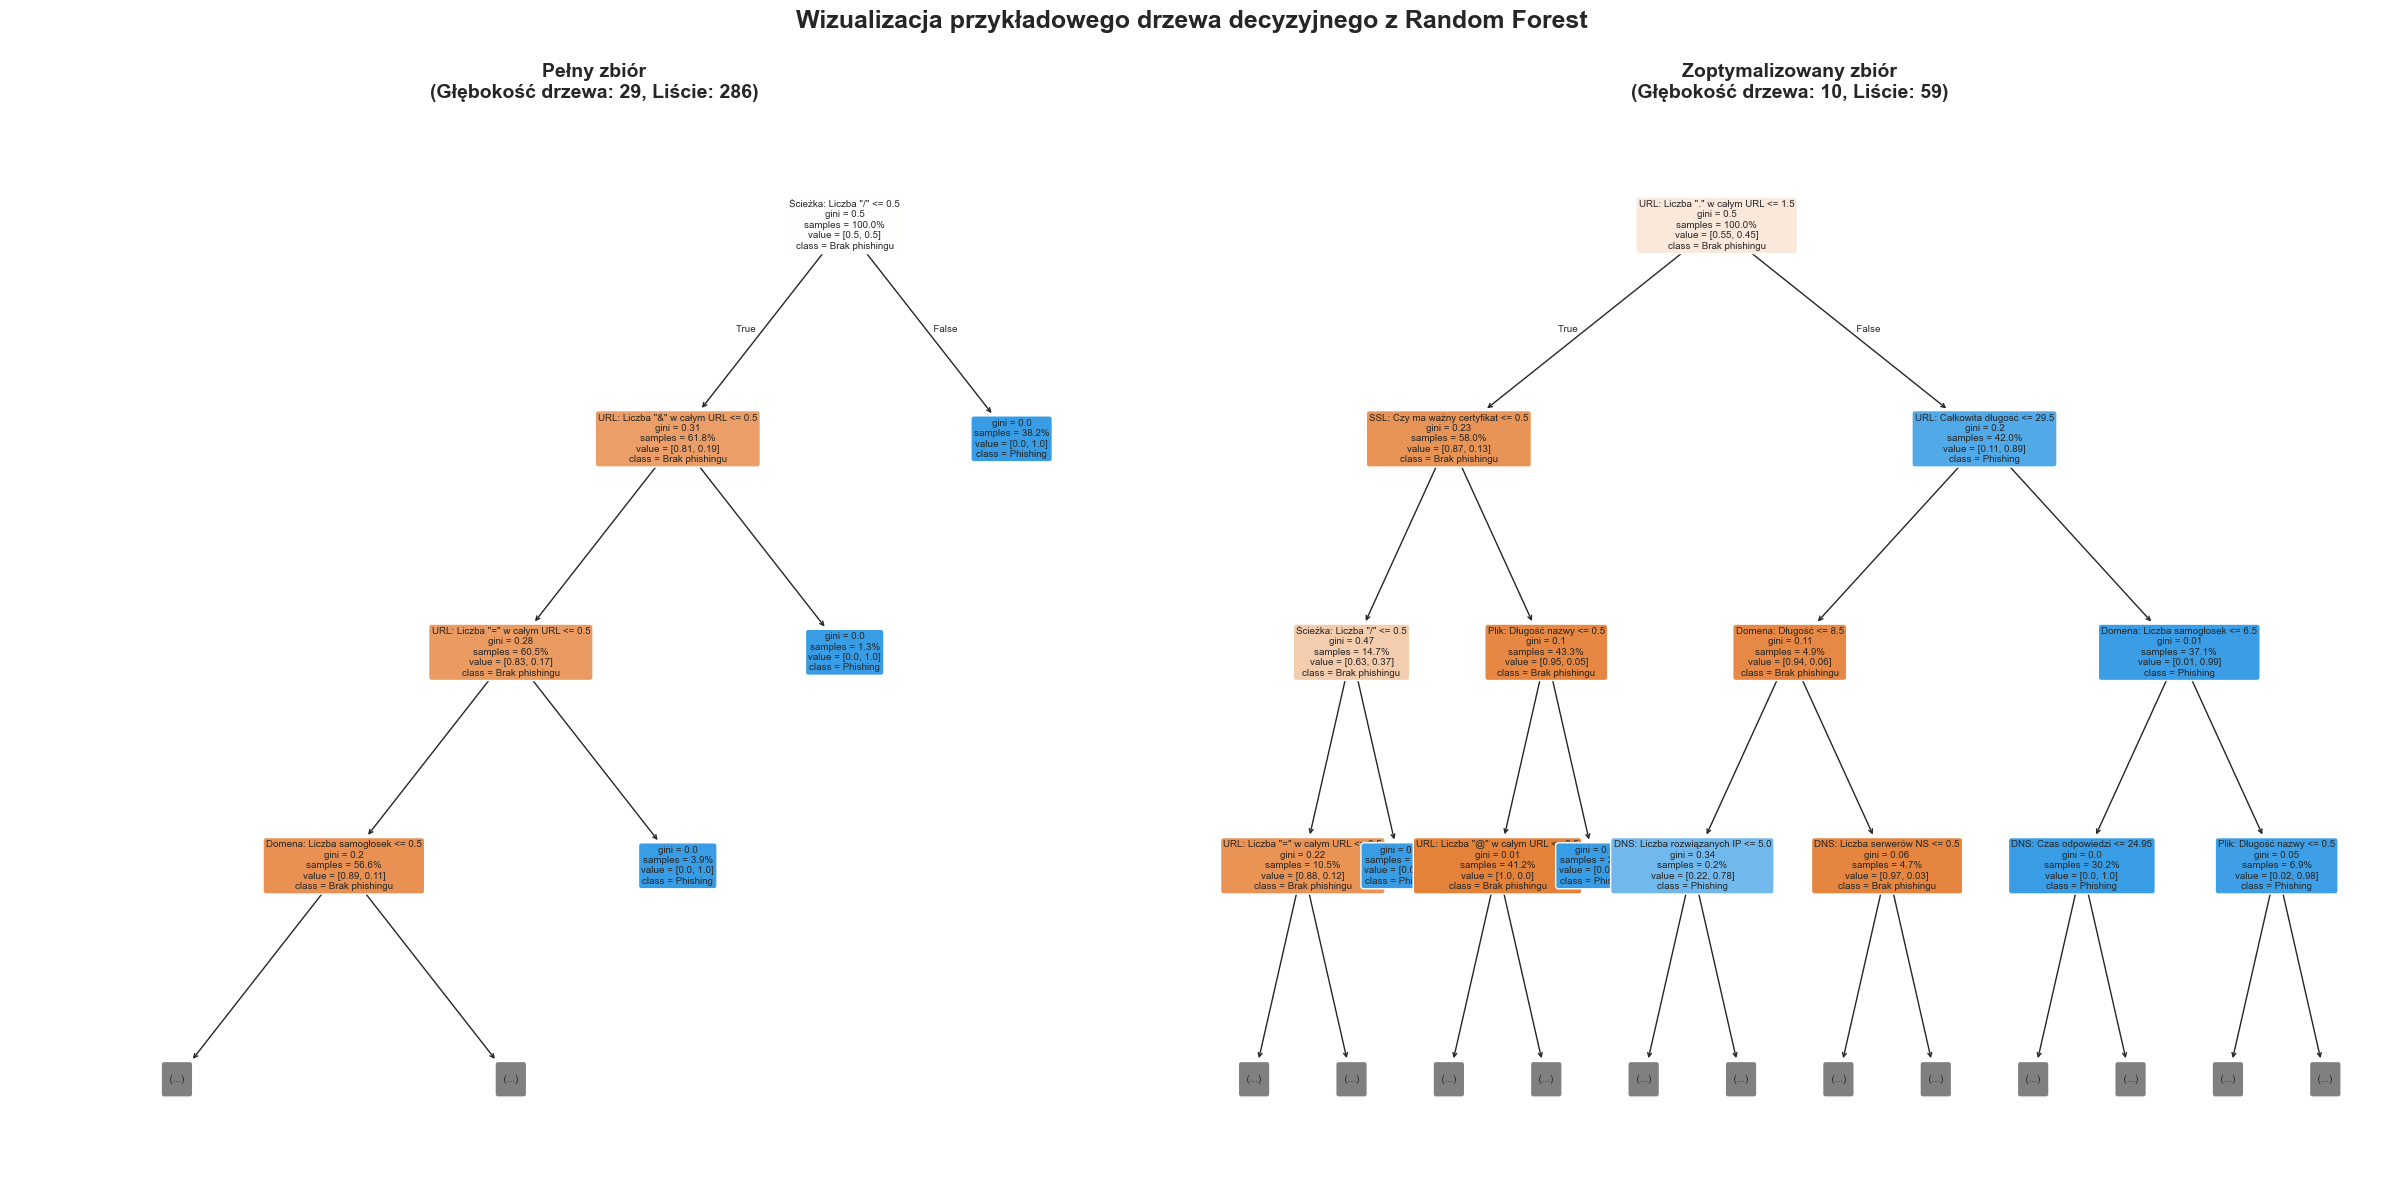

✅ Wizualizacja przykładowego drzewa zapisana

STATYSTYKI DRZEW W LESIE

Pełny zbiór:
  • Liczba drzew w lesie: 100
  • Średnia głębokość drzewa: 22.41
  • Min/Max głębokość: 5/38
  • Średnia liczba liści: 172.85
  • Min/Max liczba liści: 7/398

Zoptymalizowany zbiór:
  • Liczba drzew w lesie: 200
  • Średnia głębokość drzewa: 9.51
  • Min/Max głębokość: 3/10
  • Średnia liczba liści: 39.94
  • Min/Max liczba liści: 4/147


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(24, 12))
fig.suptitle('Wizualizacja przykładowego drzewa decyzyjnego z Random Forest',
             fontsize=18, fontweight='bold', y=0.995)

dataset_names = list(trained_models.keys())

for idx, dataset_name in enumerate(dataset_names):
    model = trained_models[dataset_name]['model']
    data = train_test_data[dataset_name]
    X_train = data['X_train']

    tree = model.estimators_[0]

    feature_names_readable = [get_readable_name(col) for col in X_train.columns]

    plot_tree(tree,
              feature_names=feature_names_readable,
              class_names=['Brak phishingu', 'Phishing'],
              filled=True,
              rounded=True,
              fontsize=7,
              max_depth=3,
              ax=axes[idx],
              proportion=True,
              precision=2,
              impurity=True)

    axes[idx].set_title(f'{dataset_name}\n(Głębokość drzewa: {tree.get_depth()}, Liście: {tree.get_n_leaves()})',
                       fontweight='bold', fontsize=14, pad=15)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/random_forest_tree_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja przykładowego drzewa zapisana")

print("\n" + "="*80)
print("STATYSTYKI DRZEW W LESIE")
print("="*80)

for dataset_name in dataset_names:
    model = trained_models[dataset_name]['model']
    tree_depths = [tree.get_depth() for tree in model.estimators_]
    tree_leaves = [tree.get_n_leaves() for tree in model.estimators_]

    print(f"\n{dataset_name}:")
    print(f"  • Liczba drzew w lesie: {len(model.estimators_)}")
    print(f"  • Średnia głębokość drzewa: {np.mean(tree_depths):.2f}")
    print(f"  • Min/Max głębokość: {min(tree_depths)}/{max(tree_depths)}")
    print(f"  • Średnia liczba liści: {np.mean(tree_leaves):.2f}")
    print(f"  • Min/Max liczba liści: {min(tree_leaves)}/{max(tree_leaves)}")

## 7.1b. Ścieżka decyzyjna dla przykładowego URL


ANALIZA ŚCIEŻKI DECYZYJNEJ DLA PRZYKŁADOWYCH URL-I

URL #26877 - Prawdziwa etykieta: Phishing
Predykcja modelu: Phishing
Prawdopodobieństwo:
  • Brak phishingu: 0.0000 (0.00%)
  • Phishing: 1.0000 (100.00%)

Głosowanie drzew w lesie:
  • Głosy na 'Brak phishingu': 0/200 (0.0%)
  • Głosy na 'Phishing': 200/200 (100.0%)

Wszystkie cechy dla tego URL (indeks #26877):
  • URL: Liczba "." w całym URL                       : 3.0000
  • URL: Liczba "-" w całym URL                       : 1.0000
  • URL: Liczba "_" w całym URL                       : 0.0000
  • URL: Liczba "/" w całym URL                       : 9.0000
  • URL: Liczba "?" w całym URL                       : 0.0000
  • URL: Liczba "=" w całym URL                       : 0.0000
  • URL: Liczba "@" w całym URL                       : 0.0000
  • URL: Liczba "&" w całym URL                       : 0.0000
  • URL: Długość Top Level Domain                     : 2.0000
  • URL: Całkowita długość                            : 109.0000
 

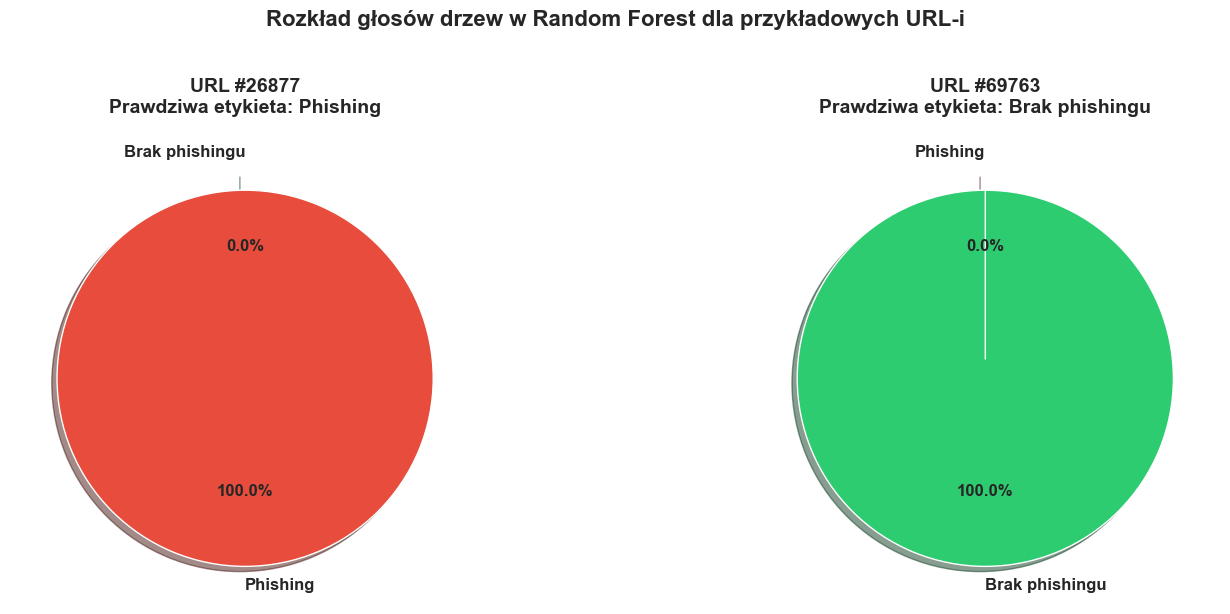


✅ Wizualizacja głosowania dla przykładowych URL-i zapisana


In [13]:
dataset_name = 'Zoptymalizowany zbiór'
model = trained_models[dataset_name]['model']
data = train_test_data[dataset_name]
X_test = data['X_test']
y_test = data['y_test']

phishing_idx = y_test[y_test == 1].index[0]
safe_idx = y_test[y_test == 0].index[0]

examples = [
    {'idx': phishing_idx, 'label': 'Phishing', 'color': '#ff7f0e'},
    {'idx': safe_idx, 'label': 'Brak phishingu', 'color': '#1f77b4'}
]

print("="*80)
print("ANALIZA ŚCIEŻKI DECYZYJNEJ DLA PRZYKŁADOWYCH URL-I")
print("="*80)

def create_example_url_from_features(feature_dict):
    """
    Tworzy przykładowy URL na podstawie wartości cech
    """
    length_url = int(feature_dict.get('length_url', 50))
    qty_hyphen_url = int(feature_dict.get('qty_hyphen_url', 0))
    qty_slash_url = int(feature_dict.get('qty_slash_url', 3))
    qty_questionmark_url = int(feature_dict.get('qty_questionmark_url', 0))
    qty_equal_url = int(feature_dict.get('qty_equal_url', 0))
    domain_length = int(feature_dict.get('domain_length', 15))

    protocol = "https://"

    domain_base = "example"
    if qty_hyphen_url > 0:
        domain_base = "ex-ample"

    tld = ".com"

    domain = domain_base + tld

    path_length = max(0, length_url - len(protocol) - domain_length - 10)
    if qty_slash_url > 3:
        path = "/page/" + "sub/" * (qty_slash_url - 4) + "file.html"
    else:
        path = "/page/file.html"

    params = ""
    if qty_questionmark_url > 0:
        params = "?id=123"
        if qty_equal_url > 1:
            params += "&param=value"

    example_url = protocol + domain + path + params

    return example_url

for example in examples:
    idx = example['idx']
    true_label = example['label']
    sample = X_test.loc[idx:idx]

    prediction = model.predict(sample)[0]
    prediction_proba = model.predict_proba(sample)[0]
    predicted_label = 'Phishing' if prediction == 1 else 'Brak phishingu'

    print(f"\n{'='*80}")
    print(f"URL #{idx} - Prawdziwa etykieta: {true_label}")
    print(f"{'='*80}")
    print(f"Predykcja modelu: {predicted_label}")
    print(f"Prawdopodobieństwo:")
    print(f"  • Brak phishingu: {prediction_proba[0]:.4f} ({prediction_proba[0]*100:.2f}%)")
    print(f"  • Phishing: {prediction_proba[1]:.4f} ({prediction_proba[1]*100:.2f}%)")

    tree_predictions = np.array([tree.predict(sample)[0] for tree in model.estimators_])
    votes_safe = np.sum(tree_predictions == 0)
    votes_phishing = np.sum(tree_predictions == 1)

    print(f"\nGłosowanie drzew w lesie:")
    print(f"  • Głosy na 'Brak phishingu': {votes_safe}/{len(model.estimators_)} ({votes_safe/len(model.estimators_)*100:.1f}%)")
    print(f"  • Głosy na 'Phishing': {votes_phishing}/{len(model.estimators_)} ({votes_phishing/len(model.estimators_)*100:.1f}%)")

    print(f"\nWszystkie cechy dla tego URL (indeks #{idx}):")
    feature_values = sample.iloc[0]
    feature_dict = {}

    for col in X_test.columns:
        readable_name = get_readable_name(col)
        value = feature_values[col]
        feature_dict[col] = value
        print(f"  • {readable_name:50s}: {value:.4f}")

    example_url = create_example_url_from_features(feature_dict)
    print(f"\n{'='*40}")
    print(f"PRZYKŁADOWY URL PASUJĄCY DO STATYSTYK:")
    print(f"{example_url}")
    print(f"{'='*40}")

    print(f"\nTop 10 najważniejszych cech (według wartości bezwzględnej):")
    feature_names_readable = [get_readable_name(col) for col in X_test.columns]

    sorted_features = sorted(
        zip(feature_names_readable, feature_values),
        key=lambda x: abs(x[1]),
        reverse=True
    )[:10]

    for feat_name, feat_val in sorted_features:
        print(f"  • {feat_name}: {feat_val:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Rozkład głosów drzew w Random Forest dla przykładowych URL-i',
             fontsize=16, fontweight='bold', y=1.02)

for idx, example in enumerate(examples):
    sample_idx = example['idx']
    label = example['label']
    color = example['color']
    sample = X_test.loc[sample_idx:sample_idx]

    tree_predictions = np.array([tree.predict(sample)[0] for tree in model.estimators_])
    votes_safe = np.sum(tree_predictions == 0)
    votes_phishing = np.sum(tree_predictions == 1)

    sizes = [votes_safe, votes_phishing]
    labels_pie = ['Brak phishingu', 'Phishing']
    colors_pie = ['#2ecc71', '#e74c3c']
    explode = (0.05, 0.05)

    axes[idx].pie(sizes, explode=explode, labels=labels_pie, colors=colors_pie,
                  autopct='%1.1f%%', shadow=True, startangle=90,
                  textprops={'fontsize': 12, 'fontweight': 'bold'})
    axes[idx].set_title(f'URL #{sample_idx}\nPrawdziwa etykieta: {label}',
                       fontweight='bold', fontsize=14, pad=15)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/random_forest_voting_examples.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Wizualizacja głosowania dla przykładowych URL-i zapisana")

## 7.2. Wpływ rozmiaru zbioru uczącego na skuteczność modelu


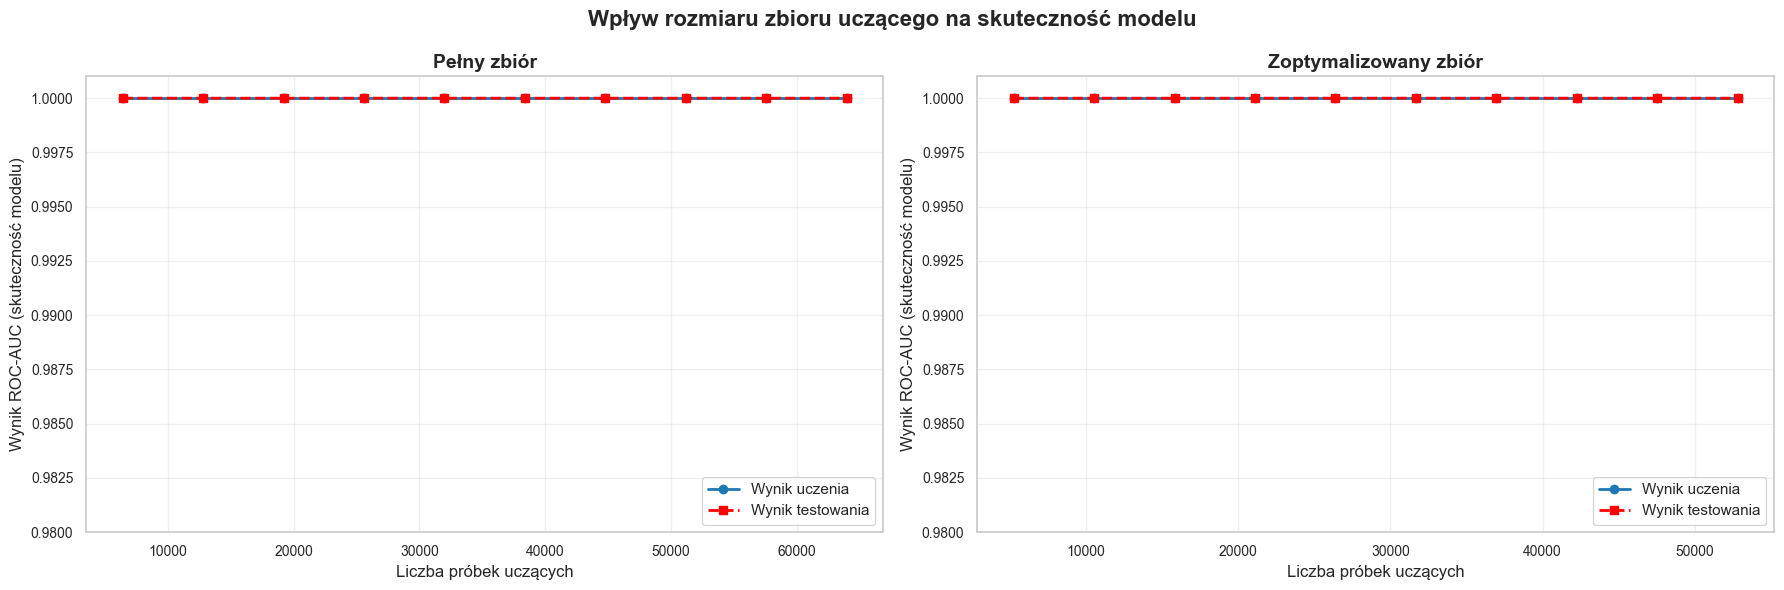

✅ Krzywe uczenia zapisane


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Wpływ rozmiaru zbioru uczącego na skuteczność modelu', fontsize=16, fontweight='bold')

dataset_names = list(trained_models.keys())

for idx, dataset_name in enumerate(dataset_names):
    model = trained_models[dataset_name]['model']
    data = train_test_data[dataset_name]
    X_train = data['X_train']
    y_train = data['y_train']

    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        cv=5,
        scoring='roc_auc',
        n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10),
        random_state=42
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    axes[idx].plot(train_sizes, train_mean, label='Wynik uczenia', color='#1f77b4', linewidth=2, marker='o')
    axes[idx].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2, color='#1f77b4')

    axes[idx].plot(train_sizes, val_mean, label='Wynik testowania', color='red', linewidth=2, marker='s', linestyle='--')
    axes[idx].fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2, color='red')

    axes[idx].set_xlabel('Liczba próbek uczących', fontsize=12)
    axes[idx].set_ylabel('Wynik ROC-AUC (skuteczność modelu)', fontsize=12)
    axes[idx].set_title(f'{dataset_name}', fontweight='bold', fontsize=14)
    axes[idx].legend(loc='lower right', fontsize=11)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([0.98, 1.001])

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/random_forest_learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Krzywe uczenia zapisane")

## 7.3. Wpływ liczby drzew (n_estimators) na skuteczność modelu


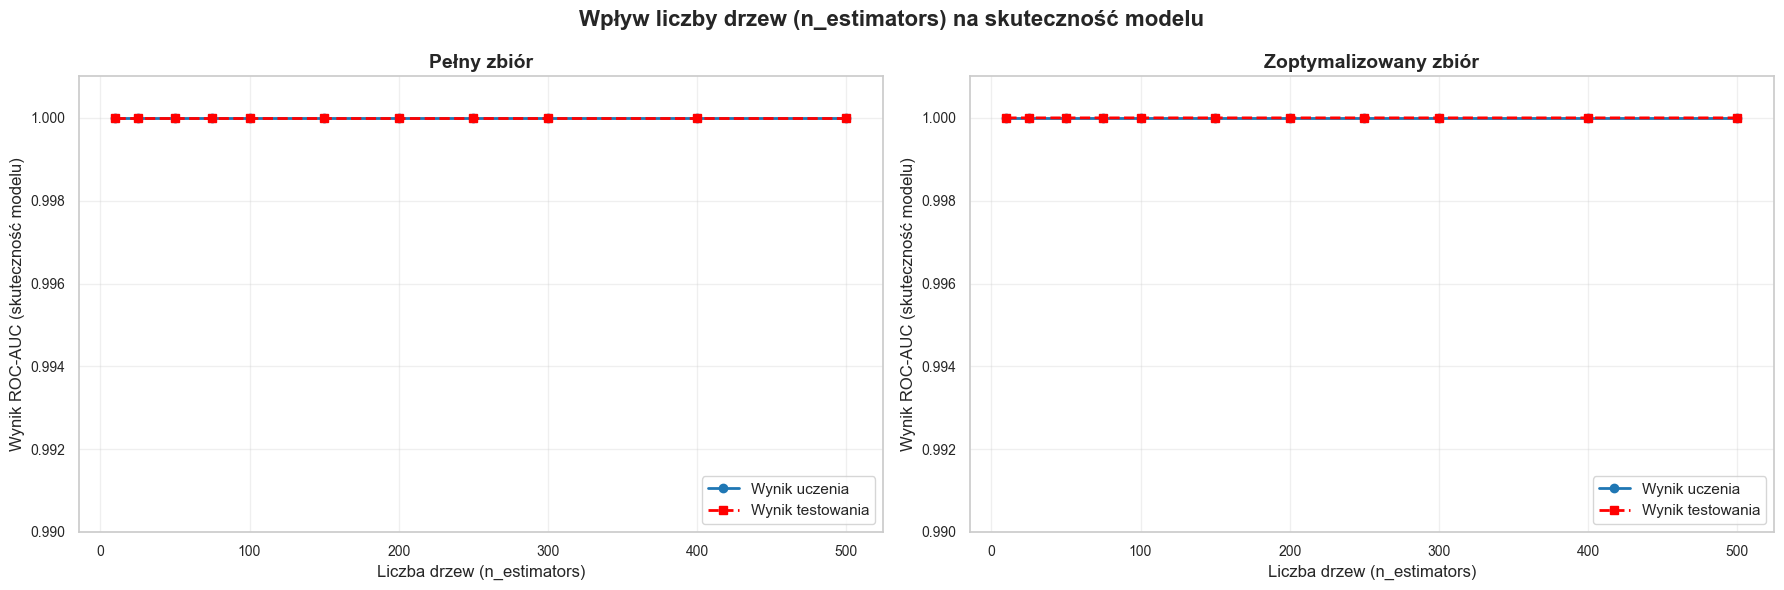

✅ Krzywe walidacyjne zapisane


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Wpływ liczby drzew (n_estimators) na skuteczność modelu', fontsize=16, fontweight='bold')

dataset_names = list(trained_models.keys())

param_range = np.array([10, 25, 50, 75, 100, 150, 200, 250, 300, 400, 500])

for idx, dataset_name in enumerate(dataset_names):
    data = train_test_data[dataset_name]
    X_train_data = data['X_train']
    y_train = data['y_train']

    model_base = RandomForestClassifier(random_state=42, n_jobs=-1)

    train_scores, val_scores = validation_curve(
        model_base, X_train_data, y_train,
        param_name='n_estimators',
        param_range=param_range,
        cv=5,
        scoring='roc_auc',
        n_jobs=-1
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    axes[idx].plot(param_range, train_mean, label='Wynik uczenia', color='#1f77b4', linewidth=2, marker='o')
    axes[idx].fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.2, color='#1f77b4')

    axes[idx].plot(param_range, val_mean, label='Wynik testowania', color='red', linewidth=2, marker='s', linestyle='--')
    axes[idx].fill_between(param_range, val_mean - val_std, val_mean + val_std, alpha=0.2, color='red')

    axes[idx].set_xlabel('Liczba drzew (n_estimators)', fontsize=12)
    axes[idx].set_ylabel('Wynik ROC-AUC (skuteczność modelu)', fontsize=12)
    axes[idx].set_title(f'{dataset_name}', fontweight='bold', fontsize=14)
    axes[idx].legend(loc='lower right', fontsize=11)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([0.99, 1.001])

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/random_forest_validation_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Krzywe walidacyjne zapisane")

## 7.4. Tabela porównawcza wyników


In [16]:
comparison_df = pd.DataFrame({
    'Zbiór danych': ['Pełny zbiór', 'Zoptymalizowany zbiór'],
    'Dokładność': [evaluation_results['Pełny zbiór']['accuracy'], evaluation_results['Zoptymalizowany zbiór']['accuracy']],
    'Precyzja': [evaluation_results['Pełny zbiór']['precision'], evaluation_results['Zoptymalizowany zbiór']['precision']],
    'Czułość': [evaluation_results['Pełny zbiór']['recall'], evaluation_results['Zoptymalizowany zbiór']['recall']],
    'Miara F1': [evaluation_results['Pełny zbiór']['f1'], evaluation_results['Zoptymalizowany zbiór']['f1']],
    'AUC-ROC': [evaluation_results['Pełny zbiór']['auc_roc'], evaluation_results['Zoptymalizowany zbiór']['auc_roc']],
    'Średnia CV AUC': [evaluation_results['Pełny zbiór']['cv_mean'], evaluation_results['Zoptymalizowany zbiór']['cv_mean']],
    'Odchylenie CV AUC': [evaluation_results['Pełny zbiór']['cv_std'], evaluation_results['Zoptymalizowany zbiór']['cv_std']],
    'Czas uczenia (s)': [trained_models['Pełny zbiór']['training_time'], trained_models['Zoptymalizowany zbiór']['training_time']],
    'Liczba cech': [data_splits['Pełny zbiór']['feature_count'], data_splits['Zoptymalizowany zbiór']['feature_count']]
})

comparison_df.to_csv('../data/url_corpus/random_forest_comparison.csv', index=False)
print(f"✓ Porównanie zapisane: ../data/url_corpus/random_forest_comparison.csv")
print("\nTabela porównawcza:")
print(comparison_df.to_string(index=False))

✓ Porównanie zapisane: ../data/url_corpus/random_forest_comparison.csv

Tabela porównawcza:
         Zbiór danych  Dokładność  Precyzja  Czułość  Miara F1  AUC-ROC  Średnia CV AUC  Odchylenie CV AUC  Czas uczenia (s)  Liczba cech
          Pełny zbiór    0.999850       1.0 0.999700  0.999850      1.0             1.0       4.965068e-17          3.403050          104
Zoptymalizowany zbiór    0.999939       1.0 0.999865  0.999932      1.0             1.0       0.000000e+00          3.436464           41


## 7.5. Ważność cech w obu modelach


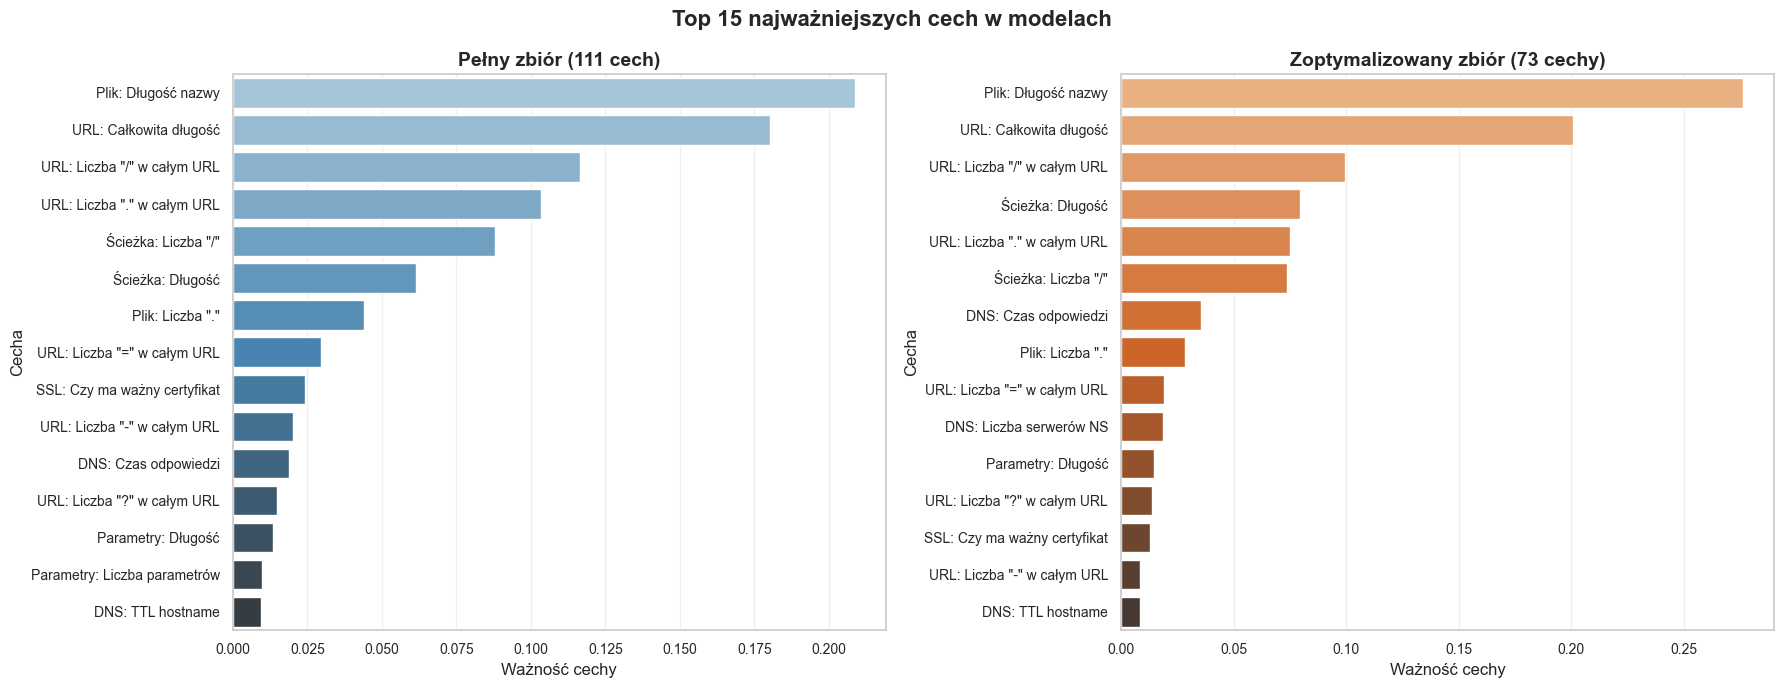

✅ Wizualizacja ważności cech zapisana


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Top 15 najważniejszych cech w modelach', fontsize=16, fontweight='bold')

dataset_names = list(trained_models.keys())
dataset_display = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']
colors_palette = ['Blues_d', 'Oranges_d']

for idx, dataset_name in enumerate(dataset_names):
    model = trained_models[dataset_name]['model']
    data = train_test_data[dataset_name]
    X = data['X_train']

    feature_importance = pd.DataFrame({
        'Cecha': [get_readable_name(col) for col in X.columns],
        'Ważność': model.feature_importances_
    }).sort_values('Ważność', ascending=False)

    top_features = feature_importance.head(15)

    sns.barplot(x='Ważność', y='Cecha', data=top_features,
                palette=colors_palette[idx], ax=axes[idx])
    axes[idx].set_xlabel('Ważność cechy', fontsize=12)
    axes[idx].set_ylabel('Cecha', fontsize=12)
    axes[idx].set_title(f'{dataset_display[idx]}', fontweight='bold', fontsize=14)
    axes[idx].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/random_forest_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja ważności cech zapisana")

## 8. Zapis modelu


In [18]:
for dataset_name, model_data in trained_models.items():
    model = model_data['model']

    if 'Pełny' in dataset_name:
        model_filename = f'{MODELS_DIR}/random_forest_full_url_corpus.pkl'
    else:
        model_filename = f'{MODELS_DIR}/random_forest_optimized_url_corpus.pkl'

    model_save_data = {
        'model': model,
        'scaler': None,
        'feature_names': train_test_data[dataset_name]['X_train'].columns.tolist(),
        'best_params': model_data['params'],
        'metrics': {
            'accuracy': evaluation_results[dataset_name]['accuracy'],
            'precision': evaluation_results[dataset_name]['precision'],
            'recall': evaluation_results[dataset_name]['recall'],
            'f1': evaluation_results[dataset_name]['f1'],
            'auc_roc': evaluation_results[dataset_name]['auc_roc'],
            'cv_auc_mean': evaluation_results[dataset_name]['cv_mean'],
            'cv_auc_std': evaluation_results[dataset_name]['cv_std']
        }
    }

    with open(model_filename, 'wb') as f:
        pickle.dump(model_save_data, f)

    print(f"✅ {dataset_name}:")
    print(f"   Model zapisany: {model_filename}")
    print(f"   Parametry: {model_data['params']}")
    print(f"   CV ROC-AUC: {model_data['cv_score']:.4f}")
    print(f"   Test ROC-AUC: {evaluation_results[dataset_name]['auc_roc']:.4f}")
    print()

print("="*80)
print("PODSUMOWANIE KOŃCOWE")
print("="*80)
print(f"\nPrzeszkolono i zapisano {len(trained_models)} modele Random Forest:")
print(f"  1. Model na pełnym zbiorze: {data_splits['Pełny zbiór']['feature_count']} cech")
print(f"  2. Model na zoptymalizowanym zbiorze: {data_splits['Zoptymalizowany zbiór']['feature_count']} cech")
print(f"\nWizualizacje zapisane w: {PLOTS_DIR}/")
print(f"Modele zapisane w: {MODELS_DIR}/")


✅ Pełny zbiór:
   Model zapisany: ../models/random_forest/random_forest_full_url_corpus.pkl
   Parametry: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
   CV ROC-AUC: 1.0000
   Test ROC-AUC: 1.0000

✅ Zoptymalizowany zbiór:
   Model zapisany: ../models/random_forest/random_forest_optimized_url_corpus.pkl
   Parametry: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
   CV ROC-AUC: 1.0000
   Test ROC-AUC: 1.0000

PODSUMOWANIE KOŃCOWE

Przeszkolono i zapisano 2 modele Random Forest:
  1. Model na pełnym zbiorze: 104 cech
  2. Model na zoptymalizowanym zbiorze: 41 cech

Wizualizacje zapisane w: ../static/plots_url_corpus/random_forest/
Modele zapisane w: ../models/random_forest/
